In [ ]:
!pip3 install tensorflow
!pip3 install tensorflow-gpu
!pip3 install numpy
!pip3 install pandas
!pip3 install matplotlib
!pip3 install Pillow
!pip3 install tqdm
!pip3 install requests

  Using cached tensorflow-gpu-2.12.0.tar.gz (2.6 kB)
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
# Temel veri işleme ve matematik işlevleri için
import numpy as np
import pandas as pd
from math import sqrt

# Görselleştirme için
import matplotlib.pyplot as plt

# Veri işleme ve dosya işlemleri için
import os
import json
import re
import collections

# Görüntü işleme için
from PIL import Image

# İlerleme çubuğu için
from tqdm import tqdm
from google.colab import drive
# HTTP istekleri için
import requests

# TensorFlow ve diğer bazı kütüphaneler, özel amaçlar için kullanılıyor olabilir.
# Eğer bu kütüphanelerin spesifik işlevlerini biliyorsanız, bunları da dahil edebilirim.
import tensorflow as tf

# Zaman ölçümü için
import time

# Rastgele sayı üretimi için
import random


In [ ]:
# Veri karıştırma ve toplu işleme için kullanılan ara bellek boyutu
# Büyük bir ara bellek boyutu, verinin daha rastgele bir şekilde karıştırılmasına yardımcı olur
# Bu da modelin genelleme yeteneğini artırır ve overfitting riskini azaltır
dataBufferSize = 500

# Gömme katmanının boyutu, kelimelerin vektörel temsillerinin boyutunu belirler
# Büyük bir gömme boyutu, kelimeler arasındaki ilişkileri daha detaylı bir şekilde yakalayabilir
# Ancak, modelin karmaşıklığını ve eğitim süresini artırır
embeddingSize = 256

# LSTM veya GRU gibi geri beslemeli katmanlardaki gizli birimlerin sayısı
# Daha fazla gizli birim, modelin daha karmaşık özellikleri öğrenmesine olanak tanır
# Ancak, modelin boyutunu ve eğitim süresini artırır
rnnUnits = 256

# Maksimum cümle uzunluğu, modelin işleyeceği en uzun cümle boyutunu belirler
# Çok uzun cümleler, eğitim sürecini yavaşlatabilir ve daha fazla bellek gerektirebilir
maxSentenceLength = 40

# Kelime dağarcığının boyutu, modelin tanıyacağı benzersiz kelimelerin sayısını belirler
# Büyük bir kelime dağarcığı, modelin daha zengin bir dil kullanmasına olanak tanır
# Ancak, modelin boyutunu ve eğitim süresini artırabilir
vocabSize = 8000

# Her eğitim adımında işlenecek veri örneklerinin sayısı
# Büyük bir batch boyutu, eğitim sürecini hızlandırabilir
# Ancak, daha fazla bellek gerektirebilir ve modelin genelleme yeteneğini etkileyebilir
batchSize = 64


In [ ]:
# API bilgilerini saklamak için kullanılan değişken
drive.mount('/content/drive')
os.chdir("/content/drive/MyDrive/Colab Notebooks/bilgisayarla_gorme")
if not os.path.isdir('data/'): # Daha açık bir kontrol

    kaggle_api = {"username": "kaayra2000",
                  "key": "e53430834cb7d44e5b4ef8f3b79ee28f"}

    with open('kaggle.json', 'w') as json_file:
        json.dump(kaggle_api, json_file)

    os.environ["KAGGLE_CONFIG_DIR"] = ""

    # Kaggle veri setini indirmek ve ayıklamak için kullanılan komutlar
    os.system('kaggle datasets download -d adityajn105/flickr8k')
    os.makedirs('data/', exist_ok=True) # Veri dizinini oluştur
    os.system('mv flickr8k.zip data/flickr8k.zip')
    os.system('unzip -q data/flickr8k.zip -d data/')
    os.remove('data/flickr8k.zip')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def create_cnn_encoder():
    # InceptionV3 modelini yükleyerek CNN Encoder olarak kullan
    inception_model = tf.keras.applications.InceptionV3(
        include_top=False,  # En üst katmanı dahil etme
        weights='imagenet',  # ImageNet ağırlıkları ile yükle
        pooling='avg'  # Global ortalama havuzlama (pooling) katmanı ekle
    )
    inception_model.trainable = False  # Modelin eğitilebilir olmasını engelle

    # Modelin çıkışını al ve yeni bir Keras modeli oluştur
    encoder_model = tf.keras.models.Model(outputs=tf.keras.layers.Reshape((-1, inception_model.output.shape[-1]))(inception_model.output),inputs=inception_model.input)
    return encoder_model

def preprocess(input_text):
    # Metni düzenleme adımlarını sıralı bir şekilde uygula
    # Metni küçük harfe çevir
    processed_text = input_text.lower().strip()
    # Noktalama işaretlerini kaldır
    processed_text = re.sub(r'[^\w\s]', '', processed_text)
    # Fazladan boşlukları tek boşluk ile değiştir
    processed_text = re.sub('\s+', ' ', processed_text)
    # Metni belirli bir formatla yeniden düzenl
    processed_text = f'[start] {processed_text} [end]'
    return processed_text

def process_image_and_caption(image_path, caption_text):
    # Resmi oku, JPEG olarak çöz ve yeniden boyutlandır
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [310, 310])

    # Renk değerlerini normalize et (0-1 aralığına dönüştür)
    image = image / 255.0

    # Altyazıyı tokenize et
    tokenized_caption = text_tokenizer(caption_text)

    return image, tokenized_caption

def process_image_from_path(image_path):
    # Resmi dosyadan oku, JPEG olarak çöz ve yeniden boyutlandır
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [310, 310])

    # Renk değerlerini normalize et (0-1 aralığına dönüştür)
    image = image / 255.0
    return image


def create_caption_for_image(image_path):
    # Resmi işle ve CNN modeliyle resim gömme işlemi yap
    processed_image = process_image_from_path(image_path)
    processed_image = tf.expand_dims(processed_image, axis=0)
    image_embedding = captioning_model.image_encoder(processed_image)
    encoded_image = captioning_model.text_encoder(image_embedding, training=False)

    # Altyazı üretimi için başlangıç tokeni
    current_caption = '[start]'

    # Altyazı oluşturma döngüsü
    for i in range(maxSentenceLength - 1):
        # Girdi tokenizasyonu ve maskeleme
        tokenized_input = text_tokenizer([current_caption])[:, :-1]
        mask = tf.cast(tokenized_input != 0, tf.int32)

        # Decoder ile sonraki kelime tahmini
        prediction = captioning_model.text_decoder(
            tokenized_input, encoded_image, training=False, mask=mask)

        # Sonraki kelimenin indeksini al ve kelimeye dönüştür
        predicted_index = np.argmax(prediction[0, i, :])
        predicted_word = index_to_word(predicted_index).numpy().decode('utf-8')

        # Eğer '[end]' tokeni gelirse döngüyü bitir
        if predicted_word == '[end]':
            break

        # Mevcut altyazıya yeni kelimeyi ekle
        current_caption += ' ' + predicted_word

    # Başlangıç tokenini kaldırarak nihai altyazıyı oluştur
    final_caption = current_caption.replace('[start] ', '')
    return final_caption


In [ ]:
class EncoderTransformer(tf.keras.layers.Layer):
    # Transformer Encoder katmanı için başlatıcı fonksiyon
    def __init__(self, embedding_dim, num_attention_heads):
        super().__init__()  # Üst sınıfın (Layer) başlatıcısını çağır

        # Katman normalizasyonları
        self.norm_layer_1 = tf.keras.layers.LayerNormalization()
        self.norm_layer_2 = tf.keras.layers.LayerNormalization()

        # Çoklu başlık dikkat mekanizması
        attention_head_dim = embedding_dim // num_attention_heads
        self.multi_head_attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_attention_heads, key_dim=attention_head_dim)

        # Yoğun katman - Çıktıları belirli bir boyuta dönüştürmek için
        self.dense_layer = tf.keras.layers.Dense(embedding_dim, activation="relu")

    # Transformer Encoder katmanı için call fonksiyonu
    def call(self, inputs, training):
        # İlk normalizasyon uygulanır ve dikkat mekanizması için hazırlık yapılır
        normed_inputs_for_attention = self.norm_layer_1(inputs)

        # Dikkat mekanizması uygulaması
        attention_output = self.multi_head_attention(
            query=normed_inputs_for_attention,
            value=normed_inputs_for_attention,
            key=normed_inputs_for_attention,
            attention_mask=None,
            training=training
        )

        # Dikkat çıktısını ve normlanmış girdileri birleştirme
        # Burada, dikkat mekanizmasının çıktısını direkt olarak yoğun katmana vermeden önce topluyoruz
        combined_attention = normed_inputs_for_attention + attention_output

        # İkinci normalizasyon işlemi uygulanır
        # Bu sefer, yoğun katman öncesi birleştirilmiş çıktıyı normalizasyon işlemine tabi tutuyoruz
        normed_combined_output = self.norm_layer_2(combined_attention)

        # Yoğun katman çıktısı elde edilir
        dense_output = self.dense_layer(normed_combined_output)

        return dense_output



class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    # Kelime ve pozisyon gömme katmanı için başlatıcı fonksiyon
    def __init__(self, vocabulary_size, embedding_dim, max_sequence_length):
        super().__init__()  # Üst sınıfın (Layer) başlatıcısını çağır

        # Token gömme katmanı
        self.token_embedding_layer = tf.keras.layers.Embedding(
            input_dim=vocabulary_size,
            output_dim=embedding_dim
        )

        # Pozisyon gömme katmanı
        self.position_embedding_layer = tf.keras.layers.Embedding(
            input_dim=max_sequence_length,
            output_dim=embedding_dim
        )

        # Pozisyon ID'leri oluşturmak için alternatif bir yaklaşım
        position_index = tf.range(start=0, limit=max_sequence_length, delta=1)
        self.position_ids = tf.reshape(position_index, shape=(1, max_sequence_length))



    # Katmanın çağrılma fonksiyonu - Forward pass işlemini tanımlar
    def call(self, token_ids):
        # Girdi tokenlarının uzunluğunu belirle
        sequence_length = tf.shape(token_ids)[-1]

        # Pozisyon ID'lerini oluştur
        position_ids = tf.range(start=0, limit=sequence_length, delta=1)
        # Pozisyon ID'leri her token için tekrarlanır
        position_ids = tf.tile(tf.expand_dims(position_ids, 0), [tf.shape(token_ids)[0], 1])

        # Token ve pozisyon gömmelerini hesapla
        token_embeddings = self.token_embedding_layer(token_ids)  # Token gömmeleri
        position_embeddings = self.position_embedding_layer(position_ids)  # Pozisyon gömmeleri

        # Toplam gömme vektörünü döndür
        return token_embeddings + position_embeddings


class DecoderTransformer(tf.keras.layers.Layer):
    # Transformer Decoder katmanı için başlatıcı fonksiyon
    def __init__(self, embedding_dim, rnn_units, num_attention_heads):
        super().__init__()  # Üst sınıfın (Layer) başlatıcısını çağır
        # Token ve pozisyon gömme katmanı
        self.token_position_embedding = TokenAndPositionEmbedding(
            text_tokenizer.vocabulary_size(), embedding_dim, maxSentenceLength)

        # İki farklı dikkat mekanizması - Kendi kendine dikkat ve encoder-decoder dikkati
        self.multi_head_attention_1 = tf.keras.layers.MultiHeadAttention(
            num_heads=num_attention_heads, key_dim=embedding_dim, dropout=0.1
        )
        self.multi_head_attention_2 = tf.keras.layers.MultiHeadAttention(
            num_heads=num_attention_heads, key_dim=embedding_dim, dropout=0.1
        )
        # Katman normalizasyonları - Her dikkat ve feed-forward katmanından sonra normalizasyon yapılır
        self.layer_norm_1 = tf.keras.layers.LayerNormalization()
        self.layer_norm_2 = tf.keras.layers.LayerNormalization()
        self.layer_norm_3 = tf.keras.layers.LayerNormalization()

        # Feed-Forward Network - İki yoğun katman içeren basit bir feed-forward ağ
        self.ffn_layer_1 = tf.keras.layers.Dense(rnn_units, activation="relu")
        self.ffn_layer_2 = tf.keras.layers.Dense(embedding_dim)

        # Çıkış katmanı - Tahminleri üretmek için son yoğun katman
        self.output_layer = tf.keras.layers.Dense(text_tokenizer.vocabulary_size(), activation="softmax")

        # Dropout katmanları - Aşırı öğrenmeyi önlemek için dropout katmanları
        self.dropout_layer_1 = tf.keras.layers.Dropout(0.28)
        self.dropout_layer_2 = tf.keras.layers.Dropout(0.52)
    # Nedensel (causal) dikkat maskesi oluşturma fonksiyonu
    def get_causal_attention_mask(self, inputs):

        # Girdi şeklini al ve batch boyutu ve dizin uzunluğunu belirle
        input_shape = tf.shape(inputs)
        batch_size, sequence_length = input_shape[0], input_shape[1]

        # Nedensel maskeyi oluştur
        i = tf.range(sequence_length)[:, tf.newaxis]
        j = tf.range(sequence_length)
        mask = tf.cast(i >= j, dtype="int32")
        mask = tf.reshape(mask, (1, input_shape[1], input_shape[1]))

        # Maskeyi tüm batch'e uygula
        mask_multiplier = tf.concat(
            [tf.expand_dims(batch_size, -1), tf.constant([1, 1], dtype=tf.int32)],
            axis=0
        )
        return tf.tile(mask, mask_multiplier)
    # Katmanın çağrılma fonksiyonu - Forward pass işlemini tanımlar
    def call(self, input_tokens, encoder_output, training, mask=None):
        # Token ve pozisyon gömme işlemi
        embeddings = self.token_position_embedding(input_tokens)

        # Nedensel ve padding maskelerini oluşturur
        causal_mask = None
        padding_mask = None
        if mask is not None:
            causal_mask = self.get_causal_attention_mask(embeddings)
            padding_mask = tf.cast(mask[:, :, tf.newaxis], dtype=tf.int32)
            combined_mask = tf.cast(mask[:, tf.newaxis, :], dtype=tf.int32)
            combined_mask = tf.minimum(combined_mask, causal_mask)

        # İlk dikkat katmanı - Kendi kendine dikkat mekanizması
        attention_output_1 = self.multi_head_attention_1(
            query=embeddings,
            value=embeddings,
            key=embeddings,
            attention_mask=combined_mask,
            training=training
        )

        # İlk normalizasyon ve çıktı
        output_1 = self.layer_norm_1(embeddings + attention_output_1)

        # İkinci dikkat katmanı - Encoder çıktısıyla dikkat mekanizması
        attention_output_2 = self.multi_head_attention_2(
            query=output_1,
            value=encoder_output,
            key=encoder_output,
            attention_mask=padding_mask,
            training=training
        )

        # İkinci normalizasyon ve çıktı
        output_2 = self.layer_norm_2(output_1 + attention_output_2)

        # Feed-forward ağ
        ffn_output = self.ffn_layer_1(output_2)
        ffn_output = self.dropout_layer_1(ffn_output, training=training)
        ffn_output = self.ffn_layer_2(ffn_output)

        # Üçüncü normalizasyon ve dropout
        ffn_output = self.layer_norm_3(ffn_output + output_2)
        ffn_output = self.dropout_layer_2(ffn_output, training=training)

        # Tahminleri hesapla
        predictions = self.output_layer(ffn_output)
        return predictions

class CaptionModelForImage(tf.keras.Model):
    # Görüntü altyazı modeli için başlatıcı fonksiyon
    def __init__(self, image_encoder_model, text_encoder, text_decoder, img_augmentation=None):
        super().__init__()  # Üst sınıfın (Model) başlatıcısını çağır
        # Modelin bileşenleri
        self.text_decoder = text_decoder          # Metni çözümleme (decode) için kullanılan model
        self.img_augmentation = img_augmentation  # Eğitim sırasında görüntü artırımı (augmentation) işlemi (isteğe bağlı)
        self.image_encoder = image_encoder_model  # Görüntüleri vektörel gömme işlemi için kullanılan model
        self.text_encoder = text_encoder          # Metin kodlaması için kullanılan model

        # Modelin performansını takip etmek için kayıp ve doğruluk izleyiciler
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")  # Ortalama kayıp değerini hesaplar
        self.accuracy_tracker = tf.keras.metrics.Mean(name="accuracy")  # Ortalama doğruluk değerini hesaplar

    # Kayıp hesaplama fonksiyonu
    def calculate_loss(self, true_labels, predicted_labels, mask):
        # Kayıp hesaplaması yapar
        raw_loss = self.loss(true_labels, predicted_labels)

        # Kayıp hesaplamasında maskeleri kullanarak sadece geçerli değerleri dikkate alır
        masked_loss = tf.boolean_mask(raw_loss, mask)

        # Maskelenmiş kaybın ortalama değerini hesaplar ve döndürür
        return tf.reduce_mean(masked_loss)


   # Eğitim adımı
    def train_step(self, data_batch):
        # Eğitim adımında modelin nasıl davranacağını tanımlar
        images, captions = data_batch

        # Görüntü artırımı uygulanırsa
        if self.img_augmentation:
            images = self.img_augmentation(images)

        # Görüntü kodlayıcıdan gömme vektörlerini alır
        img_embeddings = self.image_encoder(images)

        # Gradient hesaplaması için
        with tf.GradientTape() as tape:
            # Kayıp ve doğruluk hesaplanır
            training_loss, training_accuracy = self.compute_loss_and_accuracy(
                img_embeddings, captions
            )

        # Eğitilebilir değişkenler ve gradyanlar alınır
        trainable_variables = (
            self.text_encoder.trainable_variables + self.text_decoder.trainable_variables
        )
        gradients = tape.gradient(training_loss, trainable_variables)

        # Optimizer ile gradyanları uygular ve modeli günceller
        self.optimizer.apply_gradients(zip(gradients, trainable_variables))

        # Kayıp ve doğruluk izleyicileri güncellenir
        self.loss_tracker.update_state(training_loss)
        self.accuracy_tracker.update_state(training_accuracy)

        # Eğitim adımının kayıp ve doğruluk sonuçlarını döndürür
        return {
            "loss": self.loss_tracker.result(),
            "accuracy": self.accuracy_tracker.result()
        }


    # Test adımı
    def test_step(self, data_batch):
        # Modelin test edilme adımını tanımlar
        images, captions = data_batch

        # Görüntü kodlayıcıdan gömme vektörlerini alır
        img_embeddings = self.image_encoder(images)

        # Test modunda kayıp ve doğruluk hesaplanır
        test_loss, test_accuracy = self.compute_loss_and_accuracy(
            img_embeddings, captions, training=False
        )

        # İzleyicileri (trackers) güncelleyerek test sonuçlarını kaydeder
        self.loss_tracker.update_state(test_loss)
        self.accuracy_tracker.update_state(test_accuracy)

        # Test adımının sonuçlarını toplar ve döndürür
        return {
            "loss": self.loss_tracker.result(),
            "accuracy": self.accuracy_tracker.result()
        }


    # Doğruluk hesaplama fonksiyonu
    def calculate_accuracy(self, true_labels, predicted_labels, mask):
        # Tahmin edilen etiketlerin en yüksek olasılıklı indekslerini alır
        predicted_max_indices = tf.argmax(predicted_labels, axis=2)

        # Doğru tahminlerin doğruluk oranını hesaplar
        correct_predictions = tf.equal(true_labels, predicted_max_indices)

        # Doğruluk hesaplamasında maskeleri kullanarak sadece geçerli tahminleri dikkate alır
        masked_accuracy = tf.boolean_mask(correct_predictions, mask)

        # Maskelenmiş doğruluk oranını hesaplar ve döndürür
        return tf.reduce_mean(tf.cast(masked_accuracy, dtype=tf.float32))


    # Kayıp ve doğruluk hesaplama
    def compute_loss_and_accuracy(self, img_embeddings, captions, training=True):
        # Encoder katmanından geçirerek çıktıyı alır
        encoder_output = self.text_encoder(img_embeddings, training=training)

        # Girdi ve gerçek etiket dizilerini hazırlar
        input_seq = captions[:, :-1]  # Girdi dizisi
        true_seq = captions[:, 1:]    # Gerçek etiket dizisi

        # Maskeleri sıfır olmayan yerlerde oluşturur
        mask = (true_seq != 0)

        # Decoder ile tahminleri üretir
        predicted_seq = self.text_decoder(
            input_seq, encoder_output, training=training, mask=mask
        )

        # Kayıp ve doğruluk hesaplar
        # Kaybı hesaplarken tahminler ve gerçek değerler arasındaki farkı dikkate alır
        loss = self.calculate_loss(true_seq, predicted_seq, mask)

        # Doğruluğu hesaplarken, tahminlerin ne kadarının doğru olduğunu kontrol eder
        accuracy = self.calculate_accuracy(true_seq, predicted_seq, mask)

        return loss, accuracy

    @property
    def metrics(self):
        # Modelin metriklerini döndürür
        return [self.loss_tracker, self.accuracy_tracker]



In [ ]:
data_path = 'data'
# 'captions.txt' dosyasından verileri okuyor ve bir DataFrame oluşturuyor
caption_data = pd.read_csv(os.path.join(data_path,'captions.txt'))

# 'image' sütununu güncelleyerek her dosya yoluna 'data/Images/' ön ekini ekliyor
caption_data['image'] = caption_data['image'].apply(
    lambda img_path: os.path.join(data_path, 'Images',img_path))

# İlk beş satırı gösteriyor
caption_data.head()


,image,caption
0,data/Images/1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,data/Images/1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,data/Images/1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,data/Images/1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,data/Images/1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [ ]:
# 'caption' sütunundaki her elemanı 'preprocess' fonksiyonu ile işleyerek güncelliyor
caption_data['caption'] = caption_data['caption'].apply(preprocess)

In [ ]:
# TextVectorization katmanını kullanarak bir text_tokenizer oluştur
# Bu, metni sayısal token dizilerine dönüştürmek için kullanılacak
text_tokenizer = tf.keras.layers.TextVectorization(
    max_tokens=vocabSize,                  # Maksimum kelime dağarcığı boyutu
    standardize=None,                       # Metni standartlaştırmak için herhangi bir fonksiyon kullanılmıyor
    output_sequence_length=maxSentenceLength  # Çıktı dizisinin maksimum uzunluğu
)

# text_tokenizer'ı veri setine uyarlama
# Bu, veri setindeki tüm metinleri analiz edip bir kelime indeksi oluşturur
text_tokenizer.adapt(caption_data['caption'])

# Kelimelerden indeks numaralarına dönüşüm yapmak için kullanılacak sözlük
word_to_index = tf.keras.layers.StringLookup(
    mask_token="",                           # Maskeleme tokenı olarak boş bir string kullanılıyor
    vocabulary=text_tokenizer.get_vocabulary())  # Tokenizer'dan alınan kelime dağarcığını kullanıyor

# İndeks numaralarından kelimelere dönüşüm yapmak için kullanılacak sözlük
index_to_word = tf.keras.layers.StringLookup(
    mask_token="",                           # Maskeleme tokenı olarak boş bir string kullanılıyor
    vocabulary=text_tokenizer.get_vocabulary(),  # Tokenizer'dan alınan kelime dağarcığını kullanıyor
    invert=True)                             # İndeks-kelime çevirisi yapabilmek için invert=True olarak ayarlanıyor
# Görüntü artırma işlemleri için bir Keras Sequential modeli oluştur
augmentation_pipeline = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),  # Yatay düzlemde rastgele çevirme
        tf.keras.layers.RandomRotation(0.18),       # Rastgele rotasyon (maksimum %18'ye kadar)
        tf.keras.layers.RandomContrast(0.27),       # Rastgele kontrast değişikliği (maksimum %27'ye kadar)
    ]
)


In [ ]:
# Resimler ve ilgili altyazıları gruplamak için bir sözlük oluştur
image_to_caption_map = collections.defaultdict(list)
for image, caption in zip(caption_data['image'], caption_data['caption']):
    image_to_caption_map[image].append(caption)

# Sözlükteki anahtarları (resim yollarını) bir listeye aktar ve karıştır
image_keys = list(image_to_caption_map.keys())
random.shuffle(image_keys)

# Eğitim ve doğrulama setlerini ayırmak için bir indeks belirle
split_index = int(len(image_keys) * 0.8)
train_image_keys, val_image_keys = image_keys[:split_index], image_keys[split_index:]

# Eğitim setini oluşturmak için boş listeler başlatılıyor
training_images = []  # Bu liste, eğitim için kullanılacak resim anahtarlarını saklayacak
training_captions = []  # Bu liste ise resimlere ait altyazıları (captions) saklayacak

# 'train_image_keys' listesindeki her bir resim anahtarı için döngü başlatılıyor
for img_key in train_image_keys:
    # 'image_to_caption_map' sözlüğünde, mevcut resim anahtarı için altyazıların sayısını buluyoruz
    # bir resime birden çok altyazı verilmiş olabilir
    captions_count = len(image_to_caption_map[img_key])

    # Her resim anahtarını, ona karşılık gelen altyazı sayısı kadar 'training_images' listesine ekliyoruz
    training_images.extend([img_key] * captions_count)

    # İlgili resim anahtarına ait tüm altyazıları 'training_captions' listesine ekliyoruz
    training_captions.extend(image_to_caption_map[img_key])


# Doğrulama (validation) setini oluşturmak için boş listeler başlatılıyor
validation_images = []  # Bu liste, doğrulama için kullanılacak resim anahtarlarını saklayacak
validation_captions = []  # Bu liste ise resimlere ait altyazıları (captions) saklayacak

# 'val_image_keys' listesindeki her bir resim anahtarı için döngü başlatılıyor
for img_key in val_image_keys:
    # 'image_to_caption_map' sözlüğünde, mevcut resim anahtarı için altyazıların sayısını buluyoruz
    captions_count = len(image_to_caption_map[img_key])

    # Her resim anahtarını, ona karşılık gelen altyazı sayısı kadar 'validation_images' listesine ekliyoruz
    validation_images.extend([img_key] * captions_count)

    # İlgili resim anahtarına ait tüm altyazıları 'validation_captions' listesine ekliyoruz
    validation_captions.extend(image_to_caption_map[img_key])



In [ ]:
# Eğitim veri setini oluştur
# 'from_tensor_slices' fonksiyonu, (resimler, altyazılar) şeklinde bir dataset oluşturur
training_dataset = tf.data.Dataset.from_tensor_slices(
    (training_images, training_captions))

# Resimleri ve altyazıları işleyerek eğitim veri setini hazırla
# 'map' fonksiyonu, her bir (resim, altyazı) çifti için 'process_image_and_caption' fonksiyonunu uygular
# 'num_parallel_calls=tf.data.AUTOTUNE' ile işlemlerin paralel ve otomatik ayarlanan bir sayıda gerçekleşmesi sağlanır
training_dataset = training_dataset.map(
    process_image_and_caption, num_parallel_calls=tf.data.AUTOTUNE
).shuffle(dataBufferSize).batch(batchSize)  # Veri setini karıştır ve belirli bir parti boyutunda gruplandır

# Doğrulama veri setini oluştur
# Aynı işlemler doğrulama seti için de uygulanır
validation_dataset = tf.data.Dataset.from_tensor_slices(
    (validation_images, validation_captions))

# Resimleri ve altyazıları işleyerek doğrulama veri setini hazırla
# Eğitim setinde yapılanlar burada da tekrarlanır
validation_dataset = validation_dataset.map(
    process_image_and_caption, num_parallel_calls=tf.data.AUTOTUNE
).shuffle(dataBufferSize).batch(batchSize)

In [ ]:
# Transformer Encoder katmanını oluştur
encoder_layer = EncoderTransformer(embeddingSize, 1)

# Transformer Decoder katmanını oluştur
decoder_layer = DecoderTransformer(embeddingSize, rnnUnits, 8)

# CNN Encoder modelini oluştur
cnn_encoder_model = create_cnn_encoder()
# Görüntü altyazı modelini oluştur
captioning_model = CaptionModelForImage(
    image_encoder_model=cnn_encoder_model,  # CNN modeli
    text_encoder=encoder_layer,        # Encoder katmanı
    text_decoder=decoder_layer,        # Decoder katmanı
    img_augmentation=augmentation_pipeline  # Görüntü artırma işlemleri
)


In [ ]:
# Çapraz entropi kayıp fonksiyonunu tanımla
cross_entropy_loss = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False,
    reduction="none"
)

# Erken durdurma mekanizmasını tanımla
early_stop_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',  # Doğrulama kaybına göre izle
    patience=4,  # 4 epoch boyunca gelişme olmazsa durdur
    restore_best_weights=True  # En iyi ağırlıkları geri yükle
)

# Görüntü altyazı modelini derle
captioning_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # Adam optimizasyon algoritması ile öğrenme oranı belirle
    loss=cross_entropy_loss,  # Kayıp fonksiyonu olarak çapraz entropi kullan
    metrics=['accuracy']  # Eğitim sırasında doğruluk metriğini de izle
)


In [ ]:
# Modelin eğitim sürecini başlat
training_history = captioning_model.fit(
    training_dataset,      # Eğitim veri seti
    epochs=20,              # Toplam 20 epoch (tam veri seti üzerinden geçiş)
    validation_data=validation_dataset,  # Doğrulama veri seti
    callbacks=[early_stop_callback]  # Erken durdurma callback'ini kullan
)


Epoch 1/20
506/506 [==============================] - 4318s 8s/step - loss: 5.4380 - accuracy: 0.2067 - val_loss: 4.3725 - val_accuracy: 0.2875
Epoch 2/20
506/506 [==============================] - 234s 458ms/step - loss: 4.1313 - accuracy: 0.3113 - val_loss: 3.8263 - val_accuracy: 0.3317
Epoch 3/20
506/506 [==============================] - 230s 451ms/step - loss: 3.7540 - accuracy: 0.3393 - val_loss: 3.5936 - val_accuracy: 0.3513
Epoch 4/20
506/506 [==============================] - 265s 520ms/step - loss: 3.5405 - accuracy: 0.3554 - val_loss: 3.4581 - val_accuracy: 0.3620
Epoch 5/20
506/506 [==============================] - 228s 447ms/step - loss: 3.3887 - accuracy: 0.3681 - val_loss: 3.3542 - val_accuracy: 0.3718
Epoch 6/20
506/506 [==============================] - 230s 451ms/step - loss: 3.2692 - accuracy: 0.3767 - val_loss: 3.2865 - val_accuracy: 0.3766
Epoch 7/20
506/506 [==============================] - 229s 449ms/step - loss: 3.1736 - accuracy: 0.3860 - val_loss: 3.2325 - v

Predicted Caption: a group of people are sitting in a campfire at night



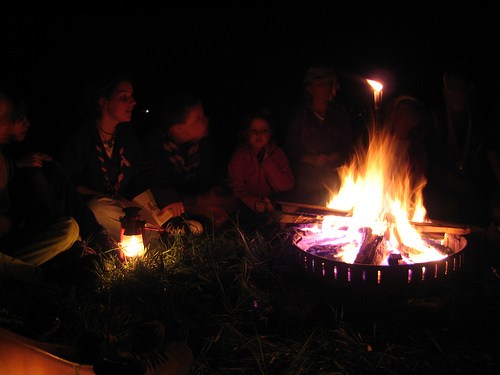

In [ ]:
image_directory = 'ornek_resimler'
image_1_path = "ates_etrafinda_insanlar.jpg"
image_2_path = "karda_yuruyen_kopekler_ve_cocuklar.jpg"
image_3_path = "kirda_kosan_kopek_1.jpg"
image_4_path = "kirda_kosan_kopek_2.jpg"
image_5_path = "ucurtma_ucuran_cocuklar.jpg"
image_6_path = "yesillikte_kosan_cocuklar.jpg"
pred_caption = create_caption_for_image(os.path.join(image_directory,image_1_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_1_path))
image

Predicted Caption: a group of children are playing in a snow



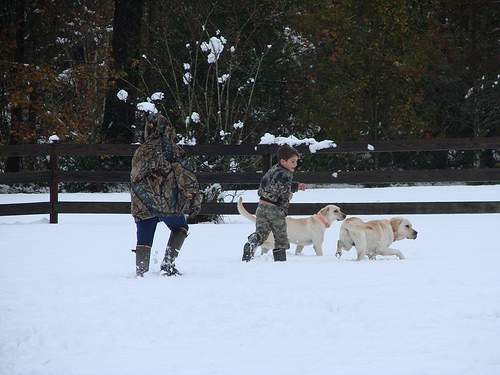

In [ ]:
pred_caption = create_caption_for_image(os.path.join(image_directory,image_2_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_2_path))
image

Predicted Caption: a small dog runs through the grass



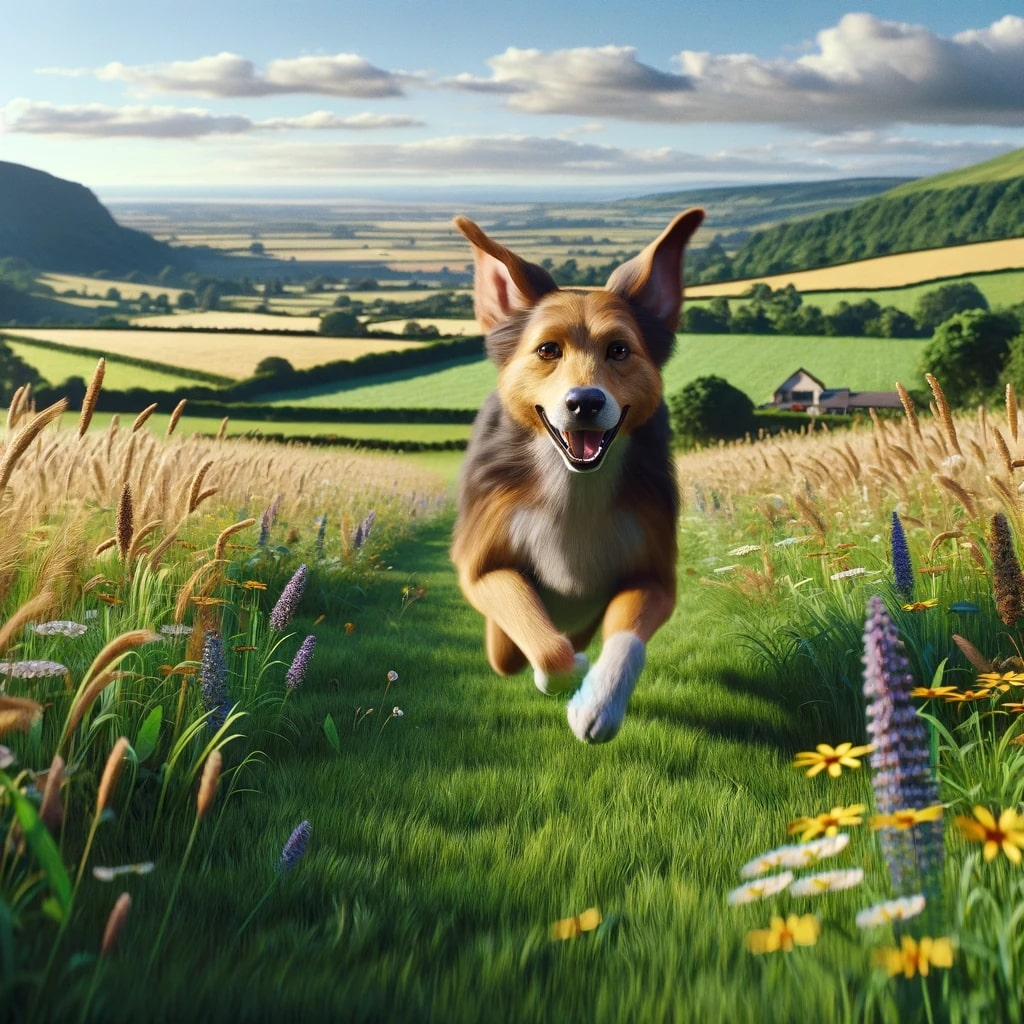

In [ ]:
pred_caption = create_caption_for_image(os.path.join(image_directory,image_3_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_3_path))
image

Predicted Caption: a small dog is jumping in the air to catch a frisbee



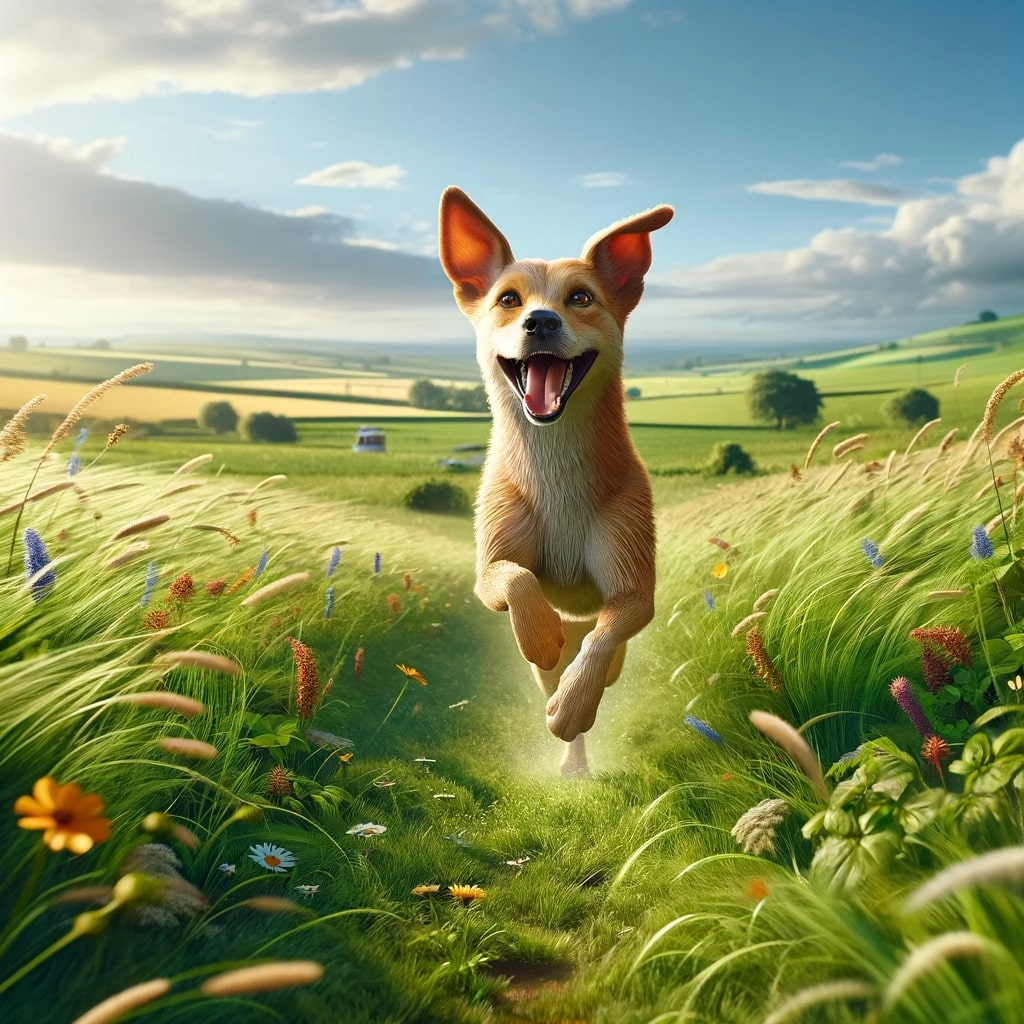

In [ ]:
pred_caption = create_caption_for_image(os.path.join(image_directory,image_4_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_4_path))
image

Predicted Caption: a group of young girls are standing in front of a crowd



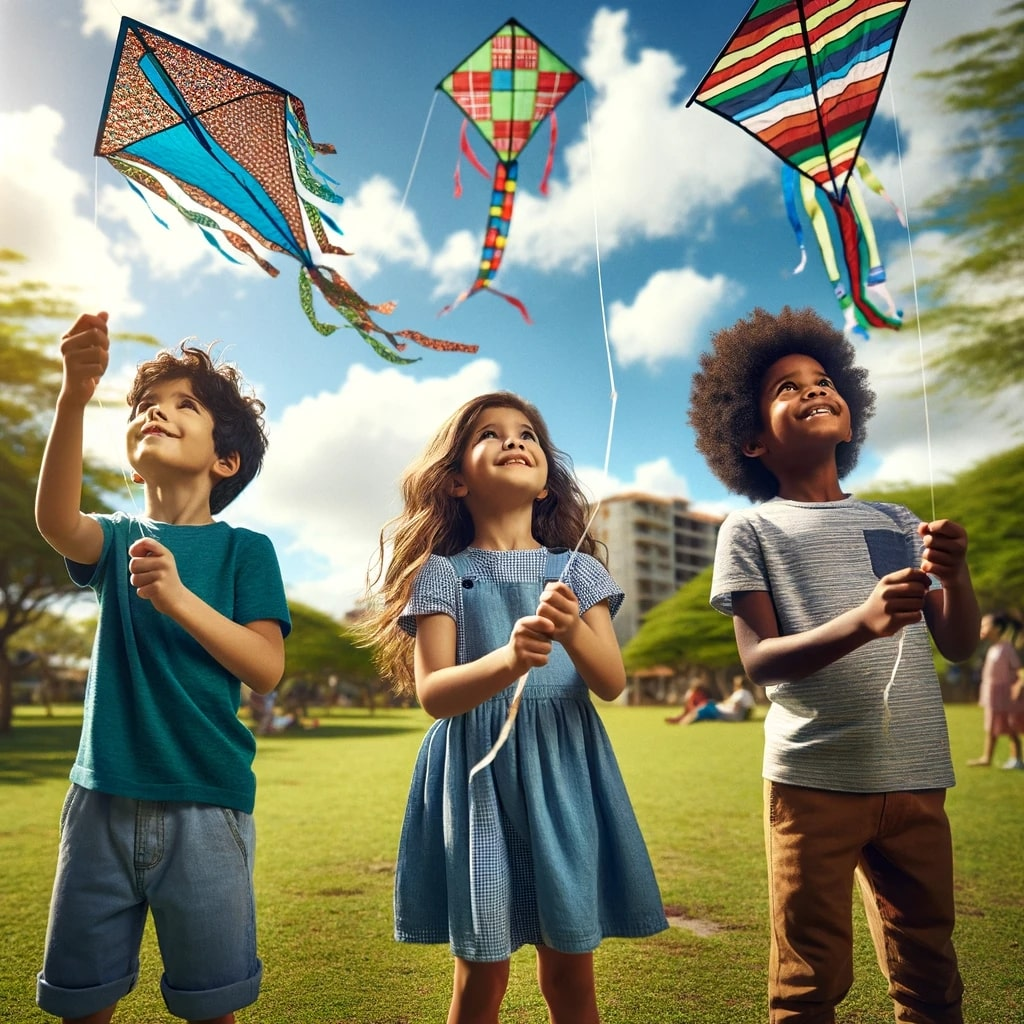

In [ ]:
pred_caption = create_caption_for_image(os.path.join(image_directory,image_5_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_5_path))
image

Predicted Caption: a girl in a pink dress is standing on a sidewalk



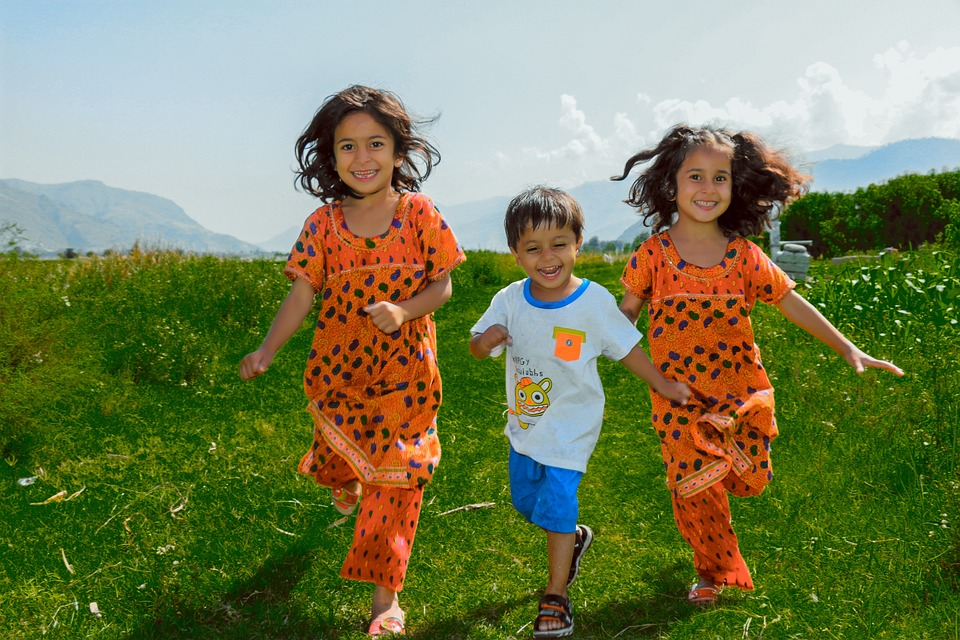

In [ ]:
pred_caption = create_caption_for_image(os.path.join(image_directory,image_6_path))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,image_6_path))
image

In [ ]:
import requests

def resim_indir(url, dosya_yolu):
    # URL'den resmi getir
    response = requests.get(url)

    # HTTP isteği başarılıysa (200 OK)
    if response.status_code == 200:
        # Resmi byte olarak yaz
        with open(dosya_yolu, 'wb') as file:
            file.write(response.content)

# Kullanım örneği
url = 'https://media.istockphoto.com/id/1175726251/tr/foto%C4%9Fraf/karda-ko%C5%9Fan-melez-k%C3%B6pek.jpg?s=2048x2048&w=is&k=20&c=hgOGxVfipRBAVGfa8H3MIH7L4Ja4VO753FfV5PW72Ww='
dosya_yolu = 'resim1.jpg'
resim_indir(url, os.path.join(image_directory, dosya_yolu))
pred_caption = create_caption_for_image(os.path.join(image_directory,dosya_yolu))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,dosya_yolu))
image

Output hidden; open in https://colab.research.google.com to view.

Predicted Caption: a child in a red jacket is standing in the snow



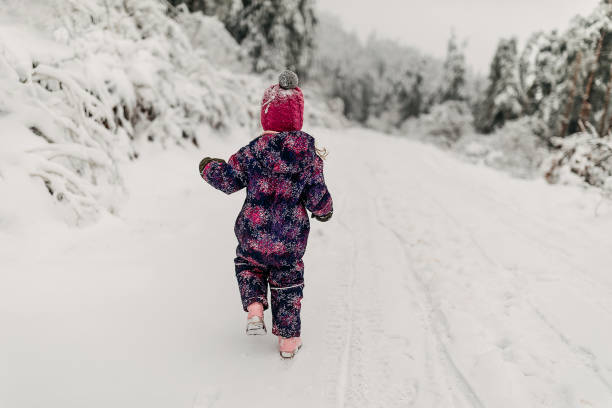

In [ ]:
# Kullanım örneği
url = 'https://media.istockphoto.com/id/1298995256/tr/foto%C4%9Fraf/karl%C4%B1-ormanda-ko%C5%9Fan-%C3%A7ocuk.jpg?b=1&s=612x612&w=0&k=20&c=Wcmd0wwcVTSjCKzwy2bErKUxPHqEcv774ANxXKQCKlM='
dosya_yolu = 'resim2.jpg'
resim_indir(url, os.path.join(image_directory, dosya_yolu))
pred_caption = create_caption_for_image(os.path.join(image_directory,dosya_yolu))
print('Predicted Caption:', pred_caption)
print()
image = Image.open(os.path.join(image_directory,dosya_yolu))
image

In [ ]:
captioning_model.save_weights('model_weights.h5')